# JS10 Lab 1: Klasifikasi Bunga Iris dengan Perceptron

Jobsheet 10, Lab 1. Perceptron di sini ditulis sendiri dengan NumPy, tanpa `scikit-learn`. Weighted sum, unit step, dan pembaruan bobot dihitung manual supaya kelihatan bagian mana yang belajar.

Kasusnya binary classification: `Iris-setosa` sebagai kelas positif, `Iris-versicolor` sebagai kelas negatif. Dataset `dataset/iris.csv` berisi 150 baris tanpa header, kolom 0-3 fitur dan kolom 4 label.

## Langkah 1 - Import Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Langkah 2 - Load Data dan Visualisasi

In [2]:
df = pd.read_csv('dataset/iris.csv', header=None)
df.head()

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


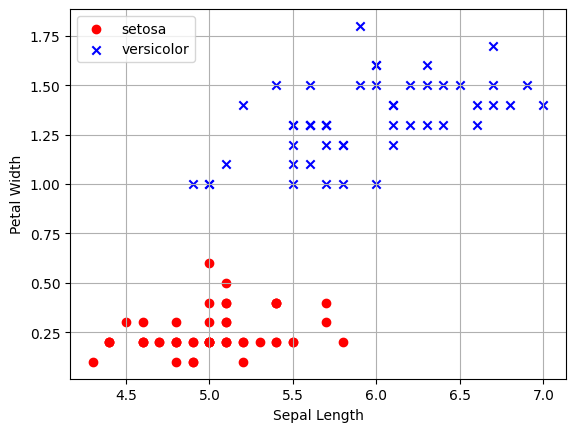

In [3]:
setosa = df[df[4] == 'Iris-setosa']
versicolor = df[df[4] == 'Iris-versicolor']

a, b = 0, 3
plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='versicolor')

plt.xlabel('Sepal Length')
plt.ylabel('Petal Width')
plt.legend(loc='upper left')
plt.grid()
plt.show()

Kedua kelas terpisah di sumbu petal width: setosa di bawah 0.6, versicolor di atas 1.0. Karena celahnya lebar, satu garis lurus cukup, jadi Perceptron layak dipakai di sini.

Catatan: modul memberi label sumbu Y "Sepal Length", padahal kolom 3 pada dataset ini adalah petal width. Label di sini sudah disesuaikan agar tidak menyesatkan.

## Langkah 3 - Membuat Kelas Perceptron

In [4]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):

        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

Bobot `w_` satu elemen lebih panjang dari jumlah fitur. `w_[0]` adalah bias, `w_[1:]` bobot tiap fitur. `update` bernilai nol saat prediksi benar, jadi bobot hanya bergeser pada data yang salah klasifikasi. `errors_` menyimpan jumlah update per epoch.

## Langkah 4 - Pilih Data dan Encoding Label

In [5]:
y = df.iloc[0:100, 4].values # pilih 100 data awal
y = np.where(y == 'Iris-setosa', -1, 1) # ganti coding label
X = df.iloc[0:100, [0, 3]].values # slice data latih

## Langkah 5 - Fitting Model

In [6]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

## Langkah 6 - Visualisasi Nilai Error Per Epoch

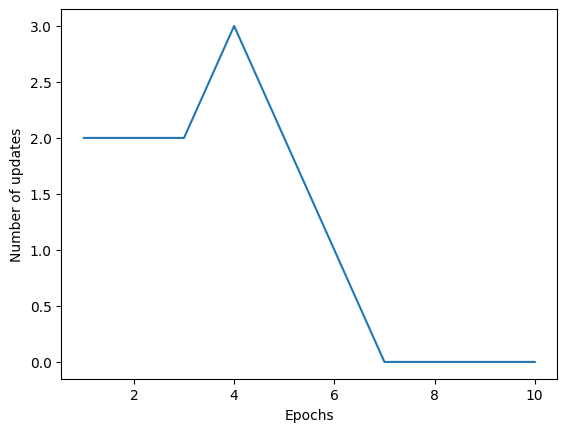

In [7]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.show()

Jumlah update per epoch adalah 2, 2, 2, 3, 2, 1, lalu 0 mulai epoch ketujuh. Selama masih ada update, bobot terus bergeser; begitu satu epoch selesai tanpa satu pun salah klasifikasi, algoritma mencapai konvergen dan epoch sisanya tidak mengubah apa-apa.

## Langkah 7 - Visualisasi Decision Boundary

In [8]:
# buat fungsi untuk plot decision region

from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions by creating a pair of grid arrays xx1 and xx2 via meshgrid function in Numpy
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))

    # use predict method to predict the class labels z of the grid points
    Z = classifier.predict(np.array([xx1.ravel(),xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # draw the contour using matplotlib
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap.colors[i], marker=markers[i], label=cl)

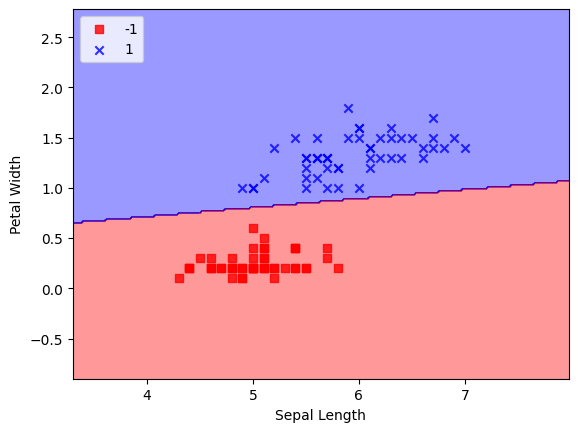

In [9]:
plot_decision_regions(X, y, classifier=ppn)
plt.xlabel('Sepal Length')
plt.ylabel('Petal Width')
plt.legend(loc='upper left')
plt.show()

Garis pemisah yang dihasilkan Perceptron jatuh tepat di celah antara setosa dan versicolor, sesuai dugaan dari scatter plot tadi.

## Langkah 8 - Evaluasi

Modul berhenti di decision boundary. Akurasi dihitung di sini supaya hasil pelatihan bisa dinyatakan sebagai angka.

In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_pred = ppn.predict(X)
print('Akurasi:', accuracy_score(y, y_pred))
print(confusion_matrix(y, y_pred))

Akurasi: 1.0
[[50  0]
 [ 0 50]]


Akurasi 100% tercapai karena kedua kelas benar-benar terpisah linear pada dua fitur yang dipilih. Ini bukan bukti model selalu bagus: iris virginica tidak ikut dilatih, dan Perceptron tetap hanya bisa memisahkan data dengan garis lurus.